# RQ1 Part B: why did inflation change in 2022?

- Part A found four regimes, with the strongest break in Aug 2022 (average 0.50% before, 2.99% after).
- Part B asks why: we check three reasons from earlier research against the data.
- no new tests and no new dates: we use Part A's regimes, one table and one chart.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The project folder, whether the notebook runs from notebooks/ or from the project folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"

dataset = pd.read_csv(ROOT / "data" / "processed" / "dataset.csv", index_col="month")
regimes = pd.read_csv(TABLES / "rq1_regimes.csv")

## 1. Three reasons

| Reason | If true, we should see |
|---|---|
| 1. Imported costs (weak yen, energy, food) | Import prices rise first, and inflation falls when import prices fall |
| 2. Firms' price-setting changed | Price plans and expectations jump and stay high, even after import prices fall |
| 3. Wages and prices | Wages rise from 2023, then service firms' price plans rise |

These predictions were written in October, before this notebook was run.

## 2. Part A's regimes

We compare the indicators across the four regimes Part A found. All dates come from Part A's table.

In [2]:
level = regimes[regimes["series"] == "level"]
breaks = level["start"].iloc[1:].tolist()  # first month of each new regime
print("Breaks from Part A:", breaks)
level[["regime", "start", "end", "months", "average"]]

Breaks from Part A: ['2010-01', '2013-07', '2022-08']


,regime,start,end,months,average
0,1,2007-01,2009-12,36,0.11
1,2,2010-01,2013-06,42,-0.79
2,3,2013-07,2022-07,109,0.50
3,4,2022-08,2026-08,49,2.99


## 3. Table: average of each indicator in each regime

- Read each row left to right, and compare the last two columns: before and after the 2022 break.
- The number before each indicator is its reason (1, 2 or 3).
- Tankan and diffusion index: % rising minus % falling.

In [3]:
# Column name -> label (the number is the reason it belongs to)
labels = {
    "target": "Target inflation (%)",
    "c2_import_prices": "1. Import prices (% YoY)",
    "c6_diffusion": "2. CPI diffusion index",
    "c6_tankan_all": "2. Tankan price plans, all firms",
    "c1_hh_expect_mean": "2. Household expectations, 1 year (%)",
    "c5_shunto": "3. Shunto wage settlement (%)",
    "c5_earnings": "3. Total cash earnings (% YoY)",
    "c6_tankan_small_services": "3. Tankan price plans, small service firms",
}

table = pd.DataFrame()
for start, end in zip(level["start"], level["end"]):
    table[f"{start} to {end}"] = dataset.loc[start:end, list(labels)].mean()
table = table.rename(index=labels).round(1)
table.index.name = "indicator"
table

,2007-01 to 2009-12,2010-01 to 2013-06,2013-07 to 2022-07,2022-08 to 2026-08
indicator,,,,
Target inflation (%),0.1,-0.8,0.5,3.0
1. Import prices (% YoY),-2.6,5.8,3.8,5.5
2. CPI diffusion index,9.1,-24.1,22.1,63.3
"2. Tankan price plans, all firms",-11.2,-19.2,0.4,32.8
"2. Household expectations, 1 year (%)",5.1,3.4,4.4,10.9
3. Shunto wage settlement (%),1.9,1.8,2.1,4.2
3. Total cash earnings (% YoY),-1.3,-0.3,0.3,2.2
"3. Tankan price plans, small service firms",-17.5,-24.4,0.5,32.9


## 4. Chart: each indicator over time

- Shows the order of events, which the averages hide: what rose first, and what happened after import prices fell in 2023.
- Dashed lines: the breaks from Part A.

Source: Bank of Japan; Statistics Bureau of Japan; Ministry of Health, Labour and Welfare.

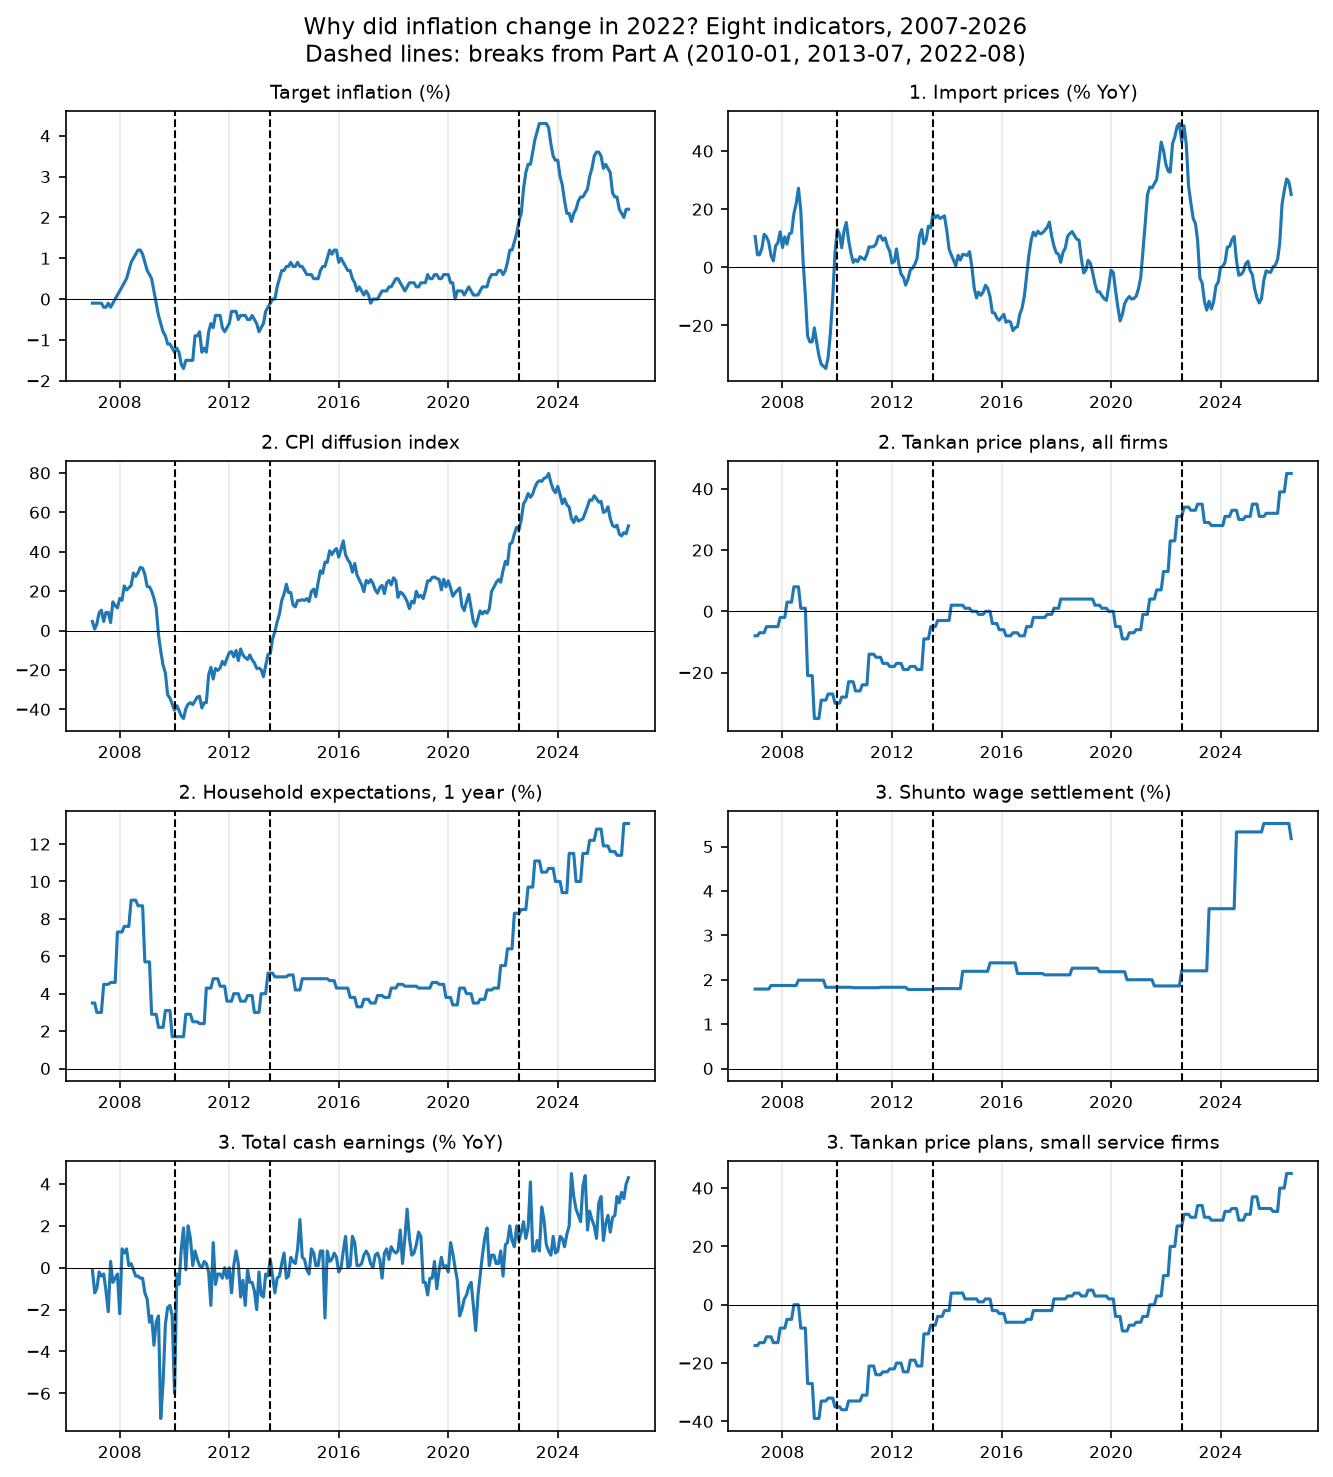

In [4]:
data = dataset.loc["2007-01":]
dates = pd.to_datetime(data.index)

fig, axes = plt.subplots(4, 2, figsize=(9, 10), dpi=150, sharex=True)
for ax, column in zip(axes.flat, labels):
    ax.plot(dates, data[column], color="tab:blue")
    for b in breaks:
        ax.axvline(pd.Timestamp(b), color="black", linestyle="--", linewidth=1)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_title(labels[column], fontsize=9)
    ax.tick_params(labelbottom=True, labelsize=8)  # years under every panel
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Why did inflation change in 2022? Eight indicators, 2007-2026\n"
             "Dashed lines: breaks from Part A (" + ", ".join(breaks) + ")", fontsize=11)
fig.tight_layout()
plt.show()

## 5. Save the table and the chart

In [5]:
table.to_csv(TABLES / "rq1_explanations.csv")
fig.savefig(FIGURES / "rq1_explanations.png")
print("Saved results/tables/rq1_explanations.csv and results/figures/rq1_explanations.png")

Saved results/tables/rq1_explanations.csv and results/figures/rq1_explanations.png


## 6. Verdict

| Reason | Question | Answer | Verdict |
|---|---|---|---|
| 1. Imported costs | When import prices fell, did inflation fall? | Only partly. Import prices rose first (from 2021, peak Jul 2022) and inflation peaked about 10 months later (May 2023). But import prices fell below a year earlier from Apr 2023, and inflation never went back near 0.5%. Over the whole new regime import prices averaged 5.5%, close to 3.8% before, while inflation averaged 3.0% against 0.5%. Compare 2008: import prices rose 27%, inflation peaked at only 1.2% and fell back within a year (the financial crisis also cut demand) | Partly consistent |
| 2. Price-setting | Did price plans and expectations jump and stay high? | Yes. Diffusion index 22.1 to 63.3, Tankan price plans 0.4 to 32.8, household expectations 4.4 to 10.9. On the chart they stay high after import prices fell in 2023 | Consistent |
| 3. Wages and prices | Did wages rise first, and service firms' price plans after? | No, the order is reversed. Service firms' price plans jumped in 2022 while Shunto stayed near 2% until 2023; wages rose later (Shunto 2.1 to 4.2 on average). Earnings grew 2.2% a year while inflation was 3.0%, so real wages fell | Partly consistent |

**Summary:** imported costs started the 2022 rise; a change in firms' and households' price behaviour kept inflation high; wages followed later. This is consistent with a new inflation regime so far.

Limits: this is a comparison of averages, not a test, and it does not model the delay from import prices to inflation. The CPI diffusion index is built from the same CPI items as inflation, so it is weaker evidence than the surveys.